<a href="https://colab.research.google.com/github/DishaKamble2005/Mono3D/blob/main/Mono3D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mono3D — Deep Learning-Based Monocular Depth Estimation
**Google Colab notebook | PyTorch | Beginner-friendly**

## Project purpose
Given one RGB photograph, estimate a *relative depth map* showing which regions appear nearer or farther.

This focused notebook uses a pretrained **Depth Anything V2 Small** neural network to generate a grayscale depth map and a color heatmap for your uploaded photograph. It demonstrates deep-learning inference with a real pretrained model, tensor processing, model parameters, and output visualization.

**Important:** this version performs inference, not model training. It does not claim that weights are updated or that the model is fine-tuned. Relative depth values are not calibrated distances in metres.

### Relevant syllabus concepts
- Neural-network architecture and trainable parameters
- Deep-learning model inference and tensor operations
- Vision backbone and depth-estimation head
- Transfer learning as a model concept (the checkpoint is pretrained; this notebook does not fine-tune it)

RNN/LSTM, RBMs, and reinforcement learning are omitted because they do not directly contribute to single-image depth estimation.

Run cells from top to bottom. A GPU is recommended but not mandatory.

In [ ]:
# Cell 1 — Check runtime
import sys, os, random, math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16
PyTorch: 2.11.0+cpu
Device: cpu


## Part B — Real-photo depth inference
This uses a pretrained model. That is **inference**, not training. The model is downloaded from Hugging Face, so this cell needs internet access in Colab.

In [ ]:
# Cell 3 — Install the pretrained-model library
%pip -q install -U transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 36.5 MB/s eta 0:00:00


In [ ]:
# Cell 4 — Load Depth Anything V2 Small
from transformers import AutoImageProcessor, AutoModelForDepthEstimation
from PIL import Image
from google.colab import files
from IPython.display import display

MODEL_ID = "depth-anything/Depth-Anything-V2-Small-hf"
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
depth_model = AutoModelForDepthEstimation.from_pretrained(MODEL_ID).to(DEVICE)
depth_model.eval()

print("Loaded:", MODEL_ID)
print("Device:", DEVICE)
print("Parameters:", f"{sum(p.numel() for p in depth_model.parameters()):,}")

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Loaded: depth-anything/Depth-Anything-V2-Small-hf
Device: cpu
Parameters: 24,785,089


### Inspect the pretrained neural network
This cell shows the model's main components and parameter count. We are inspecting a pretrained architecture; no weights are updated here.

In [ ]:
# Cell 5 — Inspect model architecture and parameters
print(depth_model)
total_params = sum(p.numel() for p in depth_model.parameters())
trainable_params = sum(p.numel() for p in depth_model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Parameters marked trainable: {trainable_params:,}")
print("Model mode:", "training" if depth_model.training else "evaluation")
print("This notebook uses inference only; no optimizer or backpropagation is run.")

DepthAnythingForDepthEstimation(
  (backbone): Dinov2Backbone(
    (embeddings): Dinov2Embeddings(
      (patch_embeddings): Dinov2PatchEmbeddings(
        (projection): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): Dinov2Encoder(
      (layer): ModuleList(
        (0-11): 12 x Dinov2Layer(
          (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
          (attention): Dinov2Attention(
            (q_proj): Linear(in_features=384, out_features=384, bias=True)
            (k_proj): Linear(in_features=384, out_features=384, bias=True)
            (v_proj): Linear(in_features=384, out_features=384, bias=True)
            (o_proj): Linear(in_features=384, out_features=384, bias=True)
          )
          (layer_scale1): Dinov2LayerScale()
          (drop_path): Identity()
          (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
          (mlp): Dinov2MLP(
            (activa

Saving Master-Bedroom-Room-Design-and-Luxury-Furniture.jpg to Master-Bedroom-Room-Design-and-Luxury-Furniture.jpg
Image: Master-Bedroom-Room-Design-and-Luxury-Furniture.jpg | size: (1800, 1200)


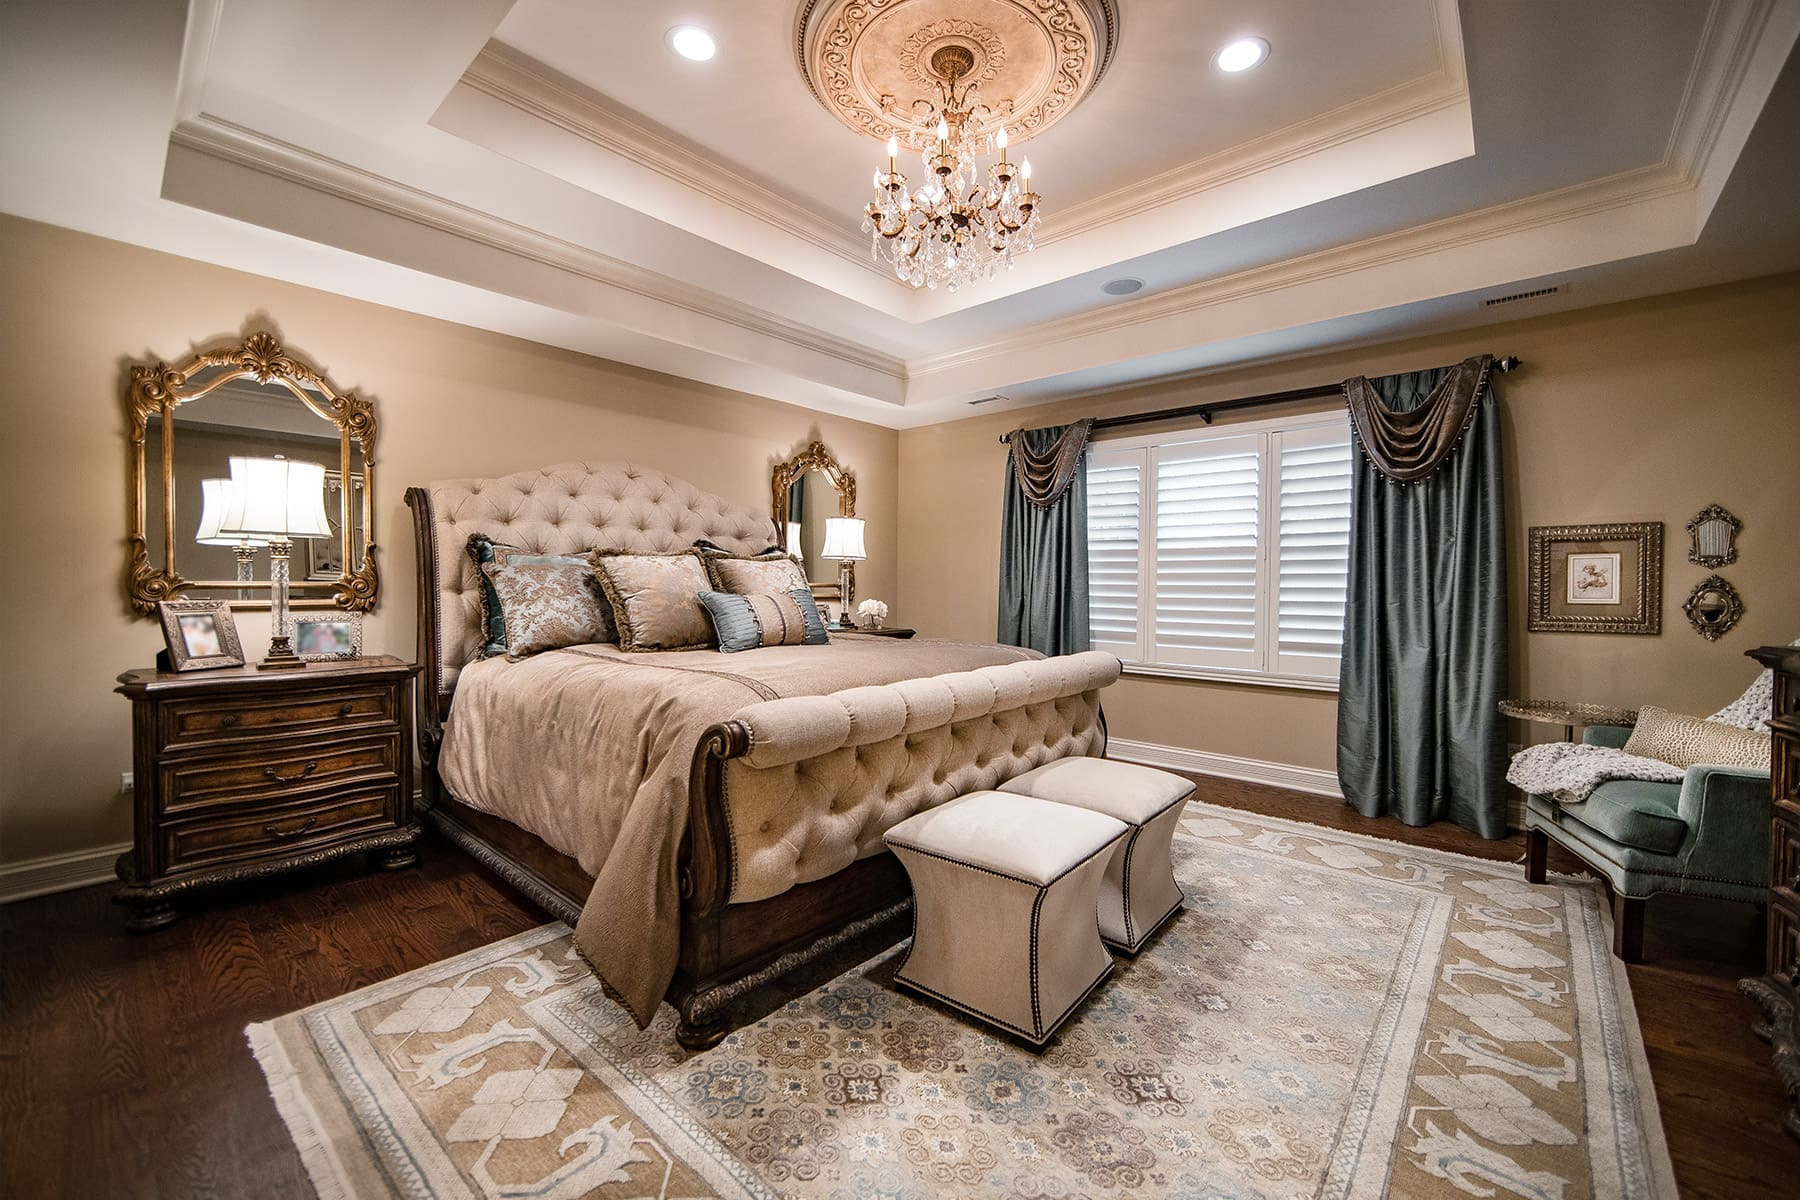

In [ ]:
# Cell 5 — Upload a clear photo (room/classroom/corridor works well)
uploaded = files.upload()
if not uploaded:
    raise ValueError("No file uploaded. Run this cell again and select a JPG/PNG.")
photo_name = next(iter(uploaded))
photo = Image.open(photo_name).convert("RGB")
print("Image:", photo_name, "| size:", photo.size)
display(photo)

Depth map shape: (1200, 1800)
Predicted range: 0.242751806974411 to 6.416784763336182


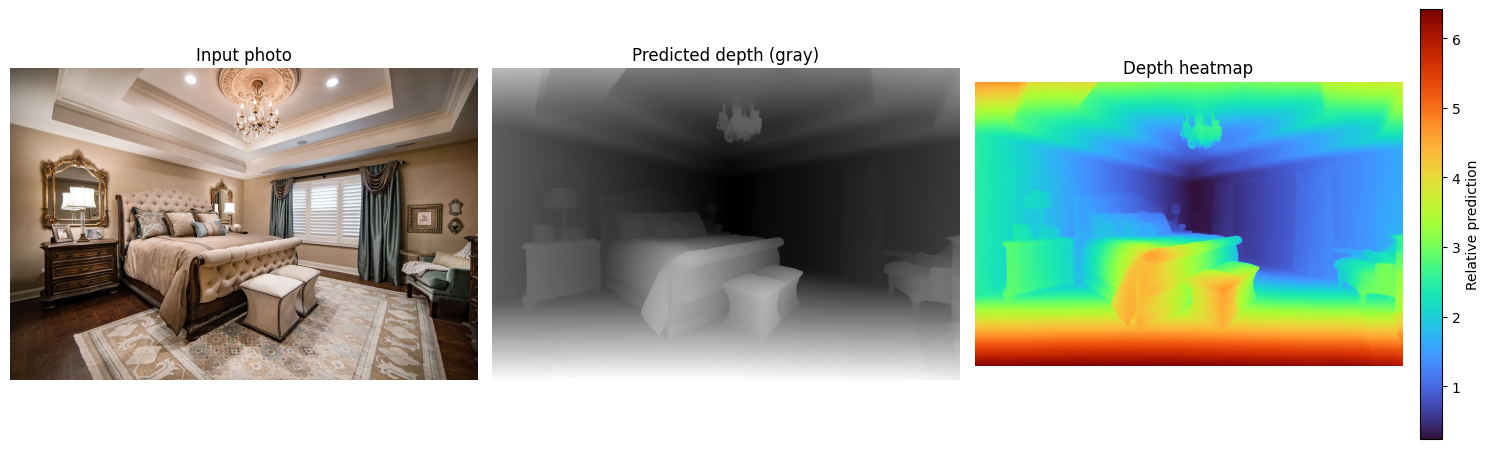

Note: values are relative depth predictions, not calibrated metres.


In [ ]:
# Cell 6 — Predict depth and visualize it
from IPython.display import display

inputs = processor(images=photo, return_tensors="pt")
inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

with torch.no_grad():
    result = depth_model(**inputs)

predicted = F.interpolate(
    result.predicted_depth.unsqueeze(1),
    size=(photo.height, photo.width),
    mode="bicubic",
    align_corners=False
).squeeze().cpu().numpy()

print("Depth map shape:", predicted.shape)
print("Predicted range:", float(predicted.min()), "to", float(predicted.max()))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(photo); ax[0].set_title("Input photo"); ax[0].axis("off")
ax[1].imshow(predicted, cmap="gray"); ax[1].set_title("Predicted depth (gray)"); ax[1].axis("off")
im = ax[2].imshow(predicted, cmap="turbo"); ax[2].set_title("Depth heatmap"); ax[2].axis("off")
fig.colorbar(im, ax=ax[2], fraction=0.046, pad=0.04, label="Relative prediction")
plt.tight_layout()
plt.show()

print("Note: values are relative depth predictions, not calibrated metres.")

In [ ]:
# Cell 7 — Save the real-photo depth map
depth_min, depth_max = float(predicted.min()), float(predicted.max())
depth_01 = (predicted - depth_min) / (depth_max - depth_min + 1e-8)
depth_png = (depth_01 * 255).astype(np.uint8)
Image.fromarray(depth_png).save("mono3d_depth_map.png")
print("Saved mono3d_depth_map.png")
files.download("mono3d_depth_map.png")

Saved mono3d_depth_map.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>